In [5]:
# !pip install torch torchvision torchaudio --index-url https://download.pytorch.org/whl/cu118
# !pip install scikit-learn

In [1]:
import pandas as pd
import numpy as np
import re
import random
import torch
import torch.nn as nn
import torch.nn.functional as F

from collections import Counter, defaultdict
from sklearn.model_selection import GroupShuffleSplit
from torch.utils.data import Dataset, DataLoader

from sklearn.metrics import classification_report, confusion_matrix

print(torch.__version__)
print(torch.cuda.is_available())

2.7.1+cu118
True


In [2]:
DEVICE = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
DEVICE

device(type='cuda')

In [3]:
df = pd.read_csv(r'../gold/aligment_all_analyst.csv', encoding='utf-8')
df.head()

,акт,обьект,по_Y,по_X,процент_нечеткого_поиска,number_act,block,conclusion,date,manufacturer,commission,invoices,projects,documents,сумма
0,ED.A009.MII.&.012.0028,not_group,NaN,Unit No: 1 Date of inspection: 2022-12-07,32.258065,0,0,0,0,0,0,0,0,0,0
1,ED.A009.MII.&.012.0028,number_act,ED.A009.MII.&.012.0028,Incoming Inspection Certificate of Materials o...,80.645161,1,0,0,0,0,0,0,0,0,1
2,ED.A009.MII.&.012.0028,not_group,NaN,Pages from 1 to 1 with Attachments on 78 pages,25.806452,0,0,0,0,0,0,0,0,0,0
3,ED.A009.MII.&.012.0028,not_group,NaN,INCOMING INSPECTION CERTIFICATE OF MATERIALS O...,19.672131,0,0,0,0,0,0,0,0,0,0
4,ED.A009.MII.&.012.0028,not_group,NaN,Manufacturer: LLC AEMZ; OMEGA METALL LLC; EVRA...,25.806452,0,0,0,0,0,0,0,0,0,0


In [4]:
# разбивка выборок
splitter = GroupShuffleSplit(n_splits=1, test_size=0.2, random_state=42)

train_idx, test_idx = next(splitter.split(df, groups=df['акт']))

train_df = df.iloc[train_idx].copy()
test_df = df.iloc[test_idx].copy()

train_acts = set(train_df['акт'])
test_acts = set(test_df['акт'])

print('Train acts:', len(train_acts))
print('Test acts:', len(test_acts))

train_acts & test_acts  #проверка

Train acts: 707
Test acts: 177


set()

In [5]:
# Базовая токенизация

TOKEN_PATTERN = re.compile(r'\w+|[^\w\s]', flags=re.UNICODE)

def tokenize(text):
    return [match.group(0) for match in TOKEN_PATTERN.finditer(text)]

In [6]:
# Словари

PAD = '<PAD>'
UNK = '<UNK>'

counter = Counter()

for text in train_df['по_X']:
    counter.update(tokenize(text))

word2idx = {
    PAD: 0,
    UNK: 1
}

for word, freq in counter.items():
    word2idx[word] = len(word2idx)

idx2word = {idx: word for word, idx in word2idx.items()}

In [7]:
# Енкодер

def encode_text(text, max_len=512):
    tokens = tokenize(text)[:max_len]
    return [word2idx.get(token, word2idx[UNK]) for token in tokens]

In [8]:
# Кодирование классов

classes = sorted(train_df['обьект'].unique())
classes.remove('not_group')
classes.insert(0, 'not_group')

class2idx = {label: i for i, label in enumerate(classes)}

idx2class = {i: label for label, i in class2idx.items()}

class2idx

{'not_group': 0,
 'block': 1,
 'commission': 2,
 'conclusion': 3,
 'date': 4,
 'documents': 5,
 'invoices': 6,
 'manufacturer': 7,
 'number_act': 8,
 'projects': 9}

In [9]:
# дата сет

class ClassificationDataset(Dataset):
    
    def __init__(self, df):
        self.texts = df['по_X'].tolist()
        self.labels = [class2idx[label] for label in df['обьект']]

    def __len__(self):
        return len(self.texts)

    def __getitem__(self, idx):

        ids = encode_text(self.texts[idx])

        return (
            torch.tensor(ids, dtype=torch.long),
            torch.tensor(self.labels[idx], dtype=torch.long))

In [10]:
# Выравнивание батчей

def classification_collate(batch):

    sequences, labels = zip(*batch)

    lengths = torch.tensor([len(x) for x in sequences], dtype=torch.long)

    max_len = max(lengths).item()

    padded = torch.zeros(len(sequences), max_len, dtype=torch.long)

    for i, seq in enumerate(sequences):
        padded[i, :len(seq)] = seq

    labels = torch.stack(labels)

    return padded, lengths, labels

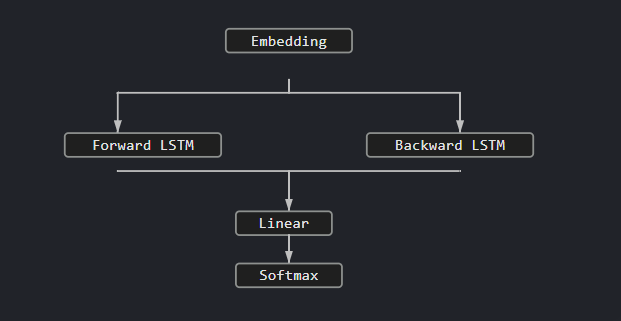

In [11]:
# Модель классификатор

class BiLSTMClassifier(nn.Module):

    def __init__(self, vocab_size, num_classes, embedding_dim=128, hidden_dim=128, dropout=0.3):
        '''
        vocab_size - сколько уникальных токенов знает модель.
        num_classes - число классов.
        embedding_dim=128- размерность эмбеддинга каждого слова.
        hidden_dim=128 - размер скрытого состояния LSTM в каждом направлении.
        dropout=0.3 - регуляризация через выключения.
        '''
        super().__init__()

        self.embedding = nn.Embedding(vocab_size, embedding_dim, padding_idx=0)

        self.lstm = nn.LSTM(
            input_size=embedding_dim,
            hidden_size=hidden_dim,
            batch_first=True,
            bidirectional=True
        )

        self.dropout = nn.Dropout(dropout)

        self.fc = nn.Linear(
            hidden_dim * 2,
            num_classes
        )

    def forward(self, x, lengths):

        embedded = self.embedding(x)

        packed = nn.utils.rnn.pack_padded_sequence(
            embedded,
            lengths.cpu(),
            batch_first=True,
            enforce_sorted=False
        )

        _, (hidden, _) = self.lstm(packed)

        forward_hidden = hidden[-2]
        backward_hidden = hidden[-1]

        combined = torch.cat([forward_hidden, backward_hidden], dim=1)

        combined = self.dropout(combined)

        return self.fc(combined)

In [12]:
# Лоадеры + модель

BATCH = 64

train_dataset = ClassificationDataset(train_df)
test_dataset = ClassificationDataset(test_df)

train_loader = DataLoader(
    train_dataset,
    batch_size=BATCH,
    shuffle=True,
    collate_fn=classification_collate #Выравнивание батчей
)

test_loader = DataLoader(
    test_dataset,
    batch_size=BATCH,
    shuffle=False,
    collate_fn=classification_collate #Выравнивание батчей
)

model_cls = BiLSTMClassifier(
    vocab_size=len(word2idx),
    num_classes=len(classes)
).to(DEVICE)

In [13]:
# Лосс и оптимизатор

class_counts = (
    train_df['обьект']
    .value_counts()
    .reindex(classes)
)

weights = 1.0 / np.sqrt(class_counts.values)

weights = weights / weights.mean()

class_weights = torch.tensor(
    weights,
    dtype=torch.float32
).to(DEVICE)

criterion = nn.CrossEntropyLoss(
    weight=class_weights
)

optimizer = torch.optim.AdamW(
    model_cls.parameters(), 
    lr=0.001, 
    weight_decay=0.01 
)

In [14]:
def train_classifier(model, train_loader, test_loader, epochs=20):

    best_loss = float('inf')

    for epoch in range(epochs):

        model.train()
        total_loss = 0

        for x, lengths, y in train_loader:

            x, y = x.to(DEVICE), y.to(DEVICE)
            optimizer.zero_grad()
            logits = model(x, lengths)
            loss = criterion(logits, y)
            loss.backward()
            nn.utils.clip_grad_norm_(model.parameters(), max_norm=5)
            optimizer.step()
            total_loss += loss.item()

        model.eval()

        val_loss = 0

        with torch.no_grad():

            for x, lengths, y in test_loader:

                x, y = x.to(DEVICE), y.to(DEVICE)
                logits = model(x, lengths)
                loss = criterion(logits, y)
                val_loss += loss.item()

        train_loss = total_loss / len(train_loader)
        val_loss /= len(test_loader)

        print(
            f'Epoch {epoch+1:>3}/{epochs:<3} | '
            f'train={train_loss:>8.4f} | '
            f'val={val_loss:>8.4f}'
        )

        if val_loss < best_loss:

            best_loss = val_loss

            torch.save(model.state_dict(), r'../models/best_classifier_10.pth')

In [15]:
# Обучение

train_classifier(model_cls, train_loader, test_loader, epochs=5)

Epoch   1/5   | train=  0.3080 | val=  0.2036
Epoch   2/5   | train=  0.1574 | val=  0.1978
Epoch   3/5   | train=  0.1300 | val=  0.2041
Epoch   4/5   | train=  0.1154 | val=  0.1979
Epoch   5/5   | train=  0.1062 | val=  0.2011


In [16]:
# Загрузка обученной модели

model_cls.load_state_dict(
    torch.load(
        r'../models/best_classifier_10.pth',
        map_location=DEVICE,
        weights_only=True
    )
)

<All keys matched successfully>

In [17]:
model_cls.eval()

y_true = []
y_pred = []

with torch.no_grad():

    for x, lengths, y in test_loader:

        x = x.to(DEVICE)

        logits = model_cls(x, lengths)

        predictions = logits.argmax(dim=1).cpu()

        y_true.extend(y.numpy())
        y_pred.extend(predictions.numpy())

print(
    classification_report(
        y_true,
        y_pred,
        target_names=classes,
        zero_division=0
    )
)

              precision    recall  f1-score   support

   not_group       0.99      0.93      0.96     10506
       block       0.44      0.98      0.61       146
  commission       0.95      0.99      0.97       598
  conclusion       1.00      1.00      1.00       177
        date       0.30      0.93      0.45       174
   documents       0.91      0.93      0.92       984
    invoices       0.81      0.92      0.86       193
manufacturer       0.67      0.96      0.79       291
  number_act       1.00      1.00      1.00       177
    projects       0.94      0.75      0.83       475

    accuracy                           0.93     13721
   macro avg       0.80      0.94      0.84     13721
weighted avg       0.96      0.93      0.94     13721

